In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score, log_loss, roc_curve, roc_auc_score

In [3]:
diabetes = pd.read_csv("pima-indians-diabetes.csv")
diabetes.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Class
0,1,85,66,29,0,26.6,0.351,31,0
1,8,183,64,0,0,23.3,0.672,32,1
2,1,89,66,23,94,28.1,0.167,21,0
3,0,137,40,35,168,43.1,2.288,33,1
4,5,116,74,0,0,25.6,0.201,30,0


In [4]:
# Split the data into features (X) and our target variable (y)

X = diabetes.drop('Class', axis=1)
y = diabetes['Class']

# Perform 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [5]:
# Create a standard scaler and scale our data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# Train and test a simple logistic regression model
logreg = LogisticRegression(max_iter=10000, random_state=42)
logreg.fit(X_train_scaled, y_train)
y_pred = logreg.predict(X_test_scaled)

# Evaluation Metrics

## Confusion Matrix

The confusion matrix is the most important metric for binary classification, because it produces all of our other metrics. It gives us the count of True Positives, False Positives, True Negatives, and False Negatives.

**True Positive** = actual and predicted class both positive

**False Positive** = actual class is negative, predicted positive (Type 1 error)

**True Negative** = actual and predicted class both negative

**False Negative** = actual class is positive, predicted negative (Type 2 error)

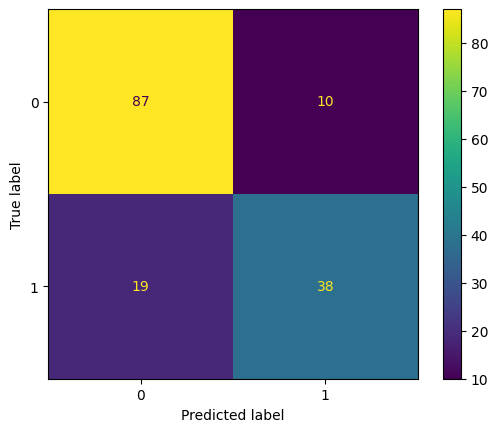

In [6]:
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=logreg.classes_)
display.plot()

In [7]:
true_negative = cm[0, 0]
false_positive = cm[0, 1]
false_negative = cm[1, 0]
true_positive = cm[1, 1]

## Accuracy

Accuracy tells us the proportion of correct predictions made by them model out of all of the predictions made. Accuracy can be misleading in the case of imbalanced datasets.

In [8]:
accuracy_manual = (true_positive + true_negative) / (true_positive + true_negative + false_positive + false_negative)
accuracy_sklearn = accuracy_score(y_test, y_pred)

print(f"Accuracy (manual): {accuracy_manual}")
print(f"Accuracy (sklearn): {accuracy_sklearn}")

Accuracy (manual): 0.8116883116883117
Accuracy (sklearn): 0.8116883116883117


## Precision

Precision measures how many of the positive predictions made by the model are actually correct. It's useful when the cost of false positives are high, such as when medical diagnosing for serious disease.

In [9]:
precision_manual = true_positive / (true_positive + false_positive)
precision_sklearn = precision_score(y_test, y_pred)

print(f"Precision (manual): {precision_manual}")
print(f"Precision (sklearn): {precision_sklearn}")

Precision (manual): 0.7916666666666666
Precision (sklearn): 0.7916666666666666


## Recall (Sensitivity)

Recall measures how many of the actual positive cases were correctly identified by the model. It is important when false negatives are more costly than false positives, such as in COVID-19 testing.

In [10]:
recall_manual = true_positive / (true_positive + false_negative)
recall_sklearn = recall_score(y_test, y_pred)

print(f"Recall (manual): {recall_manual}")
print(f"Recall (sklearn): {recall_sklearn}")

Recall (manual): 0.6666666666666666
Recall (sklearn): 0.6666666666666666


## Specificity

Specificity measures how many of the actual negative cases were correctly identified by the model. It is important when falsely identifying a negative condition as positive could have severe consequences.

In [11]:
specificity_manual = true_negative / (true_negative + false_positive)
specificity_sklearn = recall_score(y_test, y_pred, pos_label=0)

print(f"Specificity (manual): {specificity_manual}")
print(f"Specificity (sklearn): {specificity_sklearn}")

Specificity (manual): 0.8969072164948454
Specificity (sklearn): 0.8969072164948454


## F1-Score

F1-Score is the harmonic mean of precision and recall, meaning it combines both into a single number. It ranges between 0 and 1, and a high F1-score means the model peforms well on both metrics.

In [12]:
f1_score_sklearn = f1_score(y_test, y_pred)
f1_score_manual = 2 * (precision_manual * recall_manual) / (precision_manual + recall_manual)

print(f"F1-score (manual): {f1_score_manual}")
print(f"F1-score (sklearn): {f1_score_sklearn}")

F1-score (manual): 0.7238095238095237
F1-score (sklearn): 0.7238095238095238


## Logarithmic Loss

Logarithmic Loss, or log loss, measures certaintity or uncertaintity of a model's predictions. Confident, incorrect predictions are penalized heavily, and a lower log loss is better.

In [20]:
y_pred_proba = logreg.predict_proba(X_test_scaled)[:, 1]

loss = log_loss(y_test, y_pred_proba)

print(f"Log Loss: {loss:.4f}")

Log Loss: 0.4548


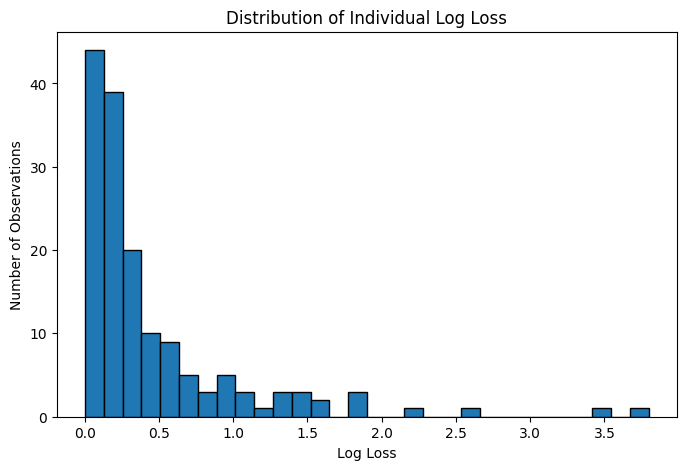

In [22]:
# Individual observation log losses
individual_loss = -(
    y_test * np.log(y_pred_proba) +
    (1 - y_test) * np.log(1 - y_pred_proba)
)

plt.figure(figsize=(8, 5))
plt.hist(individual_loss, bins=30, edgecolor='black')

plt.xlabel('Log Loss')
plt.ylabel('Number of Observations')
plt.title('Distribution of Individual Log Loss')

plt.show()

## AUC-ROC Curve

AUC-ROC curve is a popular and effective way to measure how well a binary classification model can separate its classes. AUC stands for Area Under the Curve, and ROC stands for Receiver Operating Characteristic. It uses the True Positive Rate, the False Positive Rate, and a changing threshold to assess the model's ability to make correct predictions.

As the threshold decreases, the model does not have to be as confident in its predictions, so there are cases classified as positive, meaning more True Positives and more False Positives.

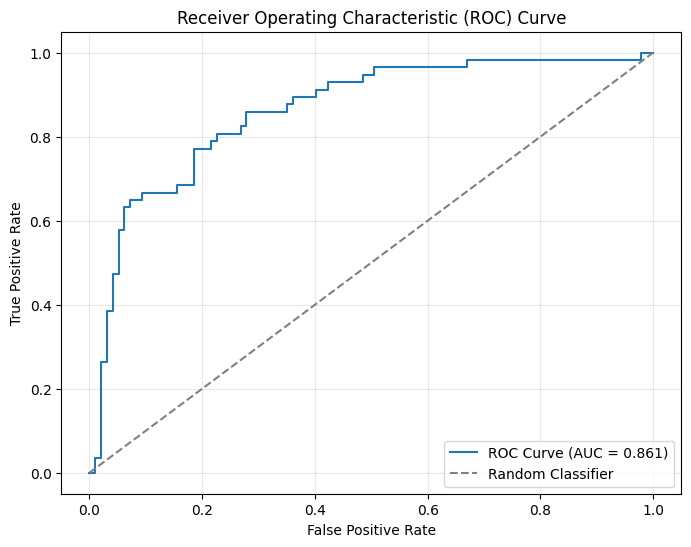

In [21]:
# Calculate ROC curve values
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

# Calculate AUC
auc = roc_auc_score(y_test, y_pred_proba)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc:.3f})')

# Add random classifier reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Classifier')

# Formatting
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()